# CNN on Intel Image Classification Dataset

**Course:** CVPR  |  **Name:** Pallab Podder Robin  |  **Student ID:** 22-48463-3

## 1. Import Libraries

I imported PyTorch and torchvision for the data and the model, matplotlib and seaborn for the plots, and scikit-learn for the classification report and confusion matrix. I also installed torchsummary (for the model summary) and kagglehub (to download the dataset). The last lines check if a GPU (cuda) is available.

In [2]:
# libraries for data and model
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import torch
import torch.nn as nn
from torch.optim import Adam
from torch import optim

# libraries for plots and evaluation
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random, os
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
%matplotlib inline

# torchsummary is for the model summary, kagglehub is to download the dataset
!pip install -q torchsummary kagglehub

# use GPU if it is available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

I used the Intel Image Classification dataset from Kaggle. It has colored images of natural scenes (around 150x150 pixels) and 6 classes: buildings, forest, glacier, mountain, sea and street. The train folder has 14,034 images and the test folder has 3,000 images, so 17,034 images in total.

From the bar chart below, the classes are almost balanced (about 2,200 to 2,500 training images in each class), so I did not need any class weights.

I picked this dataset because it has many classes and enough images to train a CNN from scratch.

In [3]:
# download the dataset from Kaggle
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

# the folder structure is a bit nested so I search for the folders that contain the class folders
train_folder, test_folder = None, None
for dirpath, dirs, files in os.walk(path):
    if "buildings" in dirs and "forest" in dirs:
        if "seg_train" in dirpath:
            train_folder = dirpath
        elif "seg_test" in dirpath:
            test_folder = dirpath

print("Train folder:", train_folder)
print("Test folder:", test_folder)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification
Train folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Test folder: /kaggle/input/intel-image-classification/seg_test/seg_test


Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


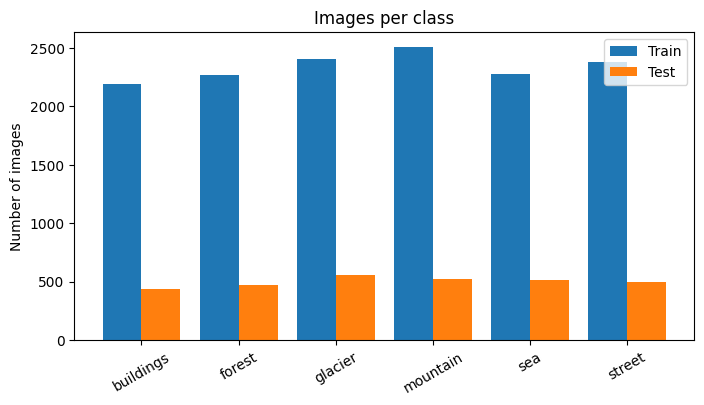

Train images: 14034
Test images: 3000


In [4]:
# count images in each class
classes = sorted(os.listdir(train_folder))
print("Classes:", classes)

train_counts = []
test_counts = []
for c in classes:
    train_counts.append(len(os.listdir(os.path.join(train_folder, c))))
    test_counts.append(len(os.listdir(os.path.join(test_folder, c))))

# bar chart of train and test images in each class
x = np.arange(len(classes))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, train_counts, 0.4, label="Train")
plt.bar(x + 0.2, test_counts, 0.4, label="Test")
plt.xticks(x, classes, rotation=30)
plt.ylabel("Number of images")
plt.title("Images per class")
plt.legend()
plt.show()

print("Train images:", sum(train_counts))
print("Test images:", sum(test_counts))

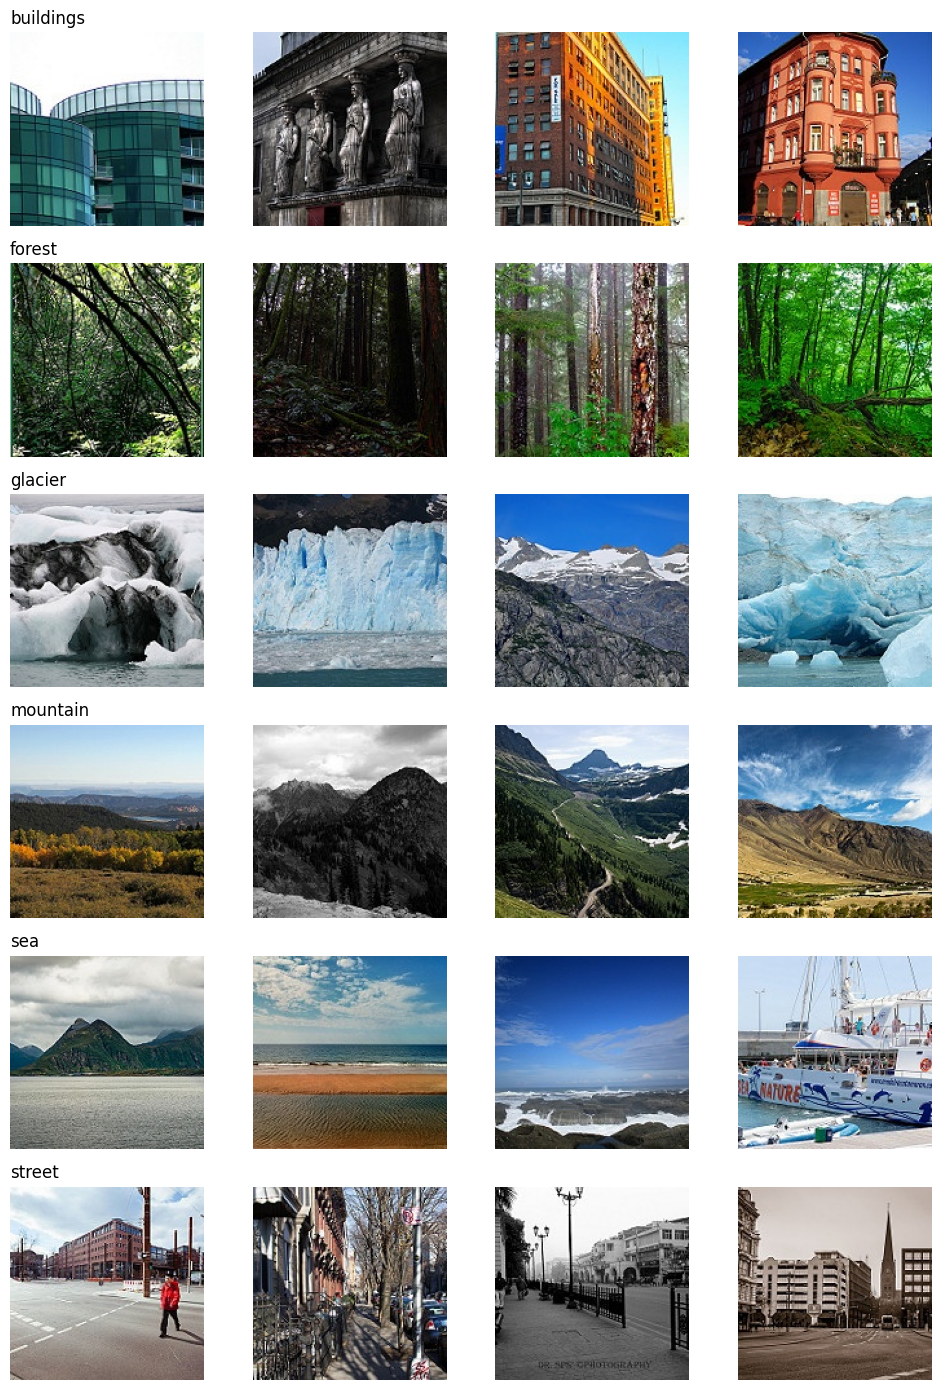

In [5]:
# show some random images from each class
plt.figure(figsize=(10, 14))
k = 1
for c in classes:
    files = random.sample(os.listdir(os.path.join(train_folder, c)), 4)
    for f in files:
        plt.subplot(len(classes), 4, k)
        plt.imshow(Image.open(os.path.join(train_folder, c, f)))
        plt.axis("off")
        if (k - 1) % 4 == 0:
            plt.title(c, loc="left")
        k += 1
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

First I resized all images to 128x128 so they have the same size, then converted them to tensors. For the training data I also added random flip, small rotation and color jitter so the model sees different versions of the images and does not overfit. I did not use vertical flip because scenes are not upside down in real life. Validation and test data only get resize and ToTensor.

The dataset has a train folder and a test folder. I used the train folder for training and split the test folder into 50% validation (1,500 images) and 50% test (1,500 images). I kept a separate test set that the model never used while training or while the scheduler was checking the validation loss, so the test accuracy is a fair result.

In [6]:
# image size for the model input
size = 128

# transforms for training data (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((size, size)),  # same size for all images
    transforms.RandomHorizontalFlip(),  # flip left-right randomly
    transforms.RandomRotation(10),  # rotate a little (up to 10 degrees)
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # change brightness and contrast a bit
    transforms.ToTensor()  # image to tensor (values between 0 and 1)
])

# validation and test data: no augmentation, only resize
val_transform = transforms.Compose([
    transforms.Resize((size, size)),  # same size for all images
    transforms.ToTensor()  # image to tensor (values between 0 and 1)
])

# ImageFolder uses the folder names as class labels
train_data = datasets.ImageFolder(train_folder, transform=train_transform)
val_test_data = datasets.ImageFolder(test_folder, transform=val_transform)

# split original test folder into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(val_test_data, [val_size, test_size])

In [7]:
# check the size of each set and the class labels
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', train_data.class_to_idx)

Dataset Summary
Train Data:  14034
Validation Data:  1500
Test Data:  1500
Classes and Indices:  {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


### Hyperparameters

- Image size = 128 (original is 150, and 128 can be divided by 2 four times for the max pooling layers)
- Batch size = 64 (fits in Colab GPU and the training is stable)
- Learning rate = 0.001 (normal starting value for Adam)
- Epochs = 20 (I will check the curves to see if it is enough or if it overfits)
- Optimizer = Adam (it adjusts the learning rate by itself so it trains fast)
- Loss = CrossEntropyLoss (because it is multi-class classification)
- Dropout = 0.4 (to reduce overfitting)

In [8]:
batch_size = 64  # number of images in one batch
learning_rate = 1e-3  # starting learning rate for Adam
epoch_number = 20  # how many times the model sees the full training data

In [9]:
# data loaders (shuffle only the training data)
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

# check the shape of one batch
x, y = next(iter(trn_dl))
print("One batch of images:", x.shape)
print("One batch of labels:", y.shape)

One batch of images: torch.Size([64, 3, 128, 128])
One batch of labels: torch.Size([64])


## 4. Define CNN Architecture

My CNN has 4 conv blocks and then a classifier. Each block has Conv2d, BatchNorm, ReLU and MaxPool. The number of filters goes 32, 64, 128, 256, so the first layers learn simple things like edges and the later layers learn bigger patterns. I used 3x3 kernel with padding 1, so only the MaxPool changes the image size (128 to 64 to 32 to 16 to 8). BatchNorm helps to make the training stable.

After that I flatten the output and use two Linear layers with dropout in between. The last layer has 6 outputs for the 6 classes. I did not add softmax because CrossEntropyLoss already includes it.

In [10]:
# this function makes the model, loss function and optimizer
def get_model():
    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),  # block 1: 3 channels (RGB) to 32 filters
        nn.BatchNorm2d(32),  # makes the training stable
        nn.ReLU(),
        nn.MaxPool2d(2),          # 128 -> 64

        nn.Conv2d(32, 64, kernel_size=3, padding=1),  # block 2
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),          # 64 -> 32

        nn.Conv2d(64, 128, kernel_size=3, padding=1),  # block 3
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),          # 32 -> 16

        nn.Conv2d(128, 256, kernel_size=3, padding=1),  # block 4
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),          # 16 -> 8

        # Classifier
        nn.Flatten(),  # 256 x 8 x 8 = 16384 values
        nn.Linear(256 * 8 * 8, 128),  # fully connected layer
        nn.ReLU(),
        nn.Dropout(0.4),  # randomly turn off 40% of the neurons while training
        nn.Linear(128, 6)  # 6 outputs for 6 classes (no softmax, CrossEntropyLoss does it)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()  # loss for multi-class classification
    optimizer = Adam(model.parameters(), lr=learning_rate)  # Adam optimizer
    return model, loss_fn, optimizer

In [11]:
# show layers, output shapes and number of parameters
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, 128, 128));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      BatchNorm2d-14          [-1, 256,

## 5. Training Loop with Validation

I made one function for training one epoch and one for validation. In validation the weights do not change and dropout is turned off. I also used ReduceLROnPlateau, so if the validation loss does not improve for 2 epochs the learning rate becomes half.

In [12]:
# train the model for one epoch, returns average loss and accuracy
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()  # training mode (dropout is on)
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)  # move the data to GPU

        optimizer.zero_grad()  # clear old gradients
        prediction = model(x)  # forward pass
        batch_loss = loss_fn(prediction, y)  # calculate the loss
        batch_loss.backward()  # backpropagation
        optimizer.step()  # update the weights

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()  # check which predictions are correct
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

# validation/test function: no gradients and no weight update
@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()  # evaluation mode (dropout is off)
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)  # move the data to GPU
        prediction = model(x)  # forward pass
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()  # check which predictions are correct
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [13]:
# make a new model so the training starts fresh
model, loss_fn, optimizer = get_model()
# halve the learning rate if validation loss does not improve for 2 epochs
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)

## Training Loop ###
# lists to save the results for the curves
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    # train for one epoch
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    # check on the validation data
    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    scheduler.step(v_loss)  # scheduler looks at the validation loss

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/20] | Train Loss: 1.3081 | Train Accuracy: 53.09% | Val Loss: 1.3285 | Val Accuracy: 54.27%
Epoch [2/20] | Train Loss: 0.9260 | Train Accuracy: 64.41% | Val Loss: 0.7748 | Val Accuracy: 71.67%
Epoch [3/20] | Train Loss: 0.8104 | Train Accuracy: 69.64% | Val Loss: 0.8727 | Val Accuracy: 68.47%
Epoch [4/20] | Train Loss: 0.7323 | Train Accuracy: 73.46% | Val Loss: 0.6529 | Val Accuracy: 78.47%
Epoch [5/20] | Train Loss: 0.6738 | Train Accuracy: 75.67% | Val Loss: 0.7151 | Val Accuracy: 75.80%
Epoch [6/20] | Train Loss: 0.6375 | Train Accuracy: 76.91% | Val Loss: 0.6931 | Val Accuracy: 77.20%
Epoch [7/20] | Train Loss: 0.6297 | Train Accuracy: 77.21% | Val Loss: 0.6696 | Val Accuracy: 76.60%
Epoch [8/20] | Train Loss: 0.5507 | Train Accuracy: 80.23% | Val Loss: 0.4612 | Val Accuracy: 84.80%
Epoch [9/20] | Train Loss: 0.5177 | Train Accuracy: 81.86% | Val Loss: 0.4771 | Val Accuracy: 84.40%
Epoch [10/20] | Train Loss: 0.5007 | Train Accuracy: 82.01% | Val Loss: 0.6659 | Val Accura

## 6. Evaluate Model on Test Set

I tested the model on the test set (1,500 images) which was not used for training or for the scheduler. I report the test loss and accuracy, then the classification report (precision, recall and F1-score of each class) and the confusion matrix to see which classes are mixed up. The last cell shows one test image with the prediction.

In [14]:
# evaluate on the test set (these images were not used in training)
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.3566 , Test Accuracy: 88.53%


In [15]:
# get predictions for the whole test set to make the report and confusion matrix
model.eval()
# lists for predicted and actual classes
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        pred = model(x).argmax(-1).cpu().numpy()  # class with the highest score
        all_preds.extend(pred)
        all_labels.extend(y.numpy())

# precision, recall and f1-score for each class
print(classification_report(all_labels, all_preds, target_names=classes))

              precision    recall  f1-score   support

   buildings       0.89      0.85      0.87       222
      forest       0.95      0.99      0.97       228
     glacier       0.86      0.82      0.84       264
    mountain       0.88      0.80      0.84       279
         sea       0.88      0.95      0.91       260
      street       0.86      0.92      0.89       247

    accuracy                           0.89      1500
   macro avg       0.89      0.89      0.89      1500
weighted avg       0.88      0.89      0.88      1500



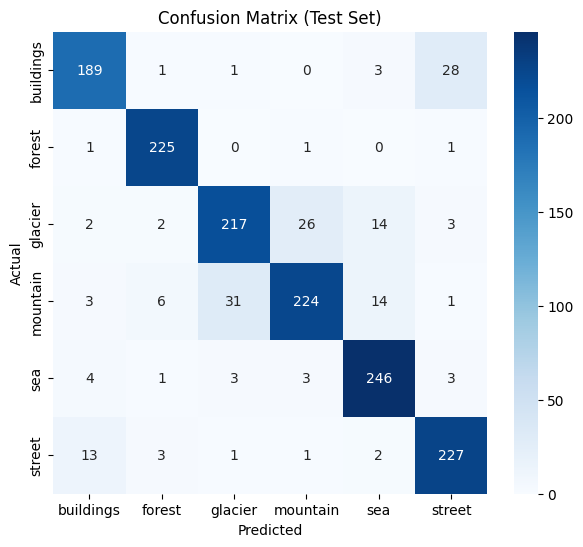

In [16]:
# rows are actual classes and columns are predicted classes
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test Set)")
plt.show()

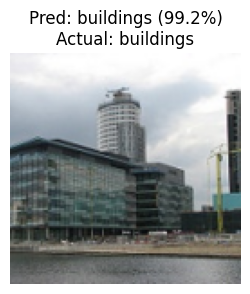

In [17]:
# check one test image
test_img, label = test_data[0]
img = test_img.unsqueeze(0).to(device)

model.eval()
output = model(img)
pred = torch.softmax(output, dim=-1)  # scores to probabilities
confidence, index = pred.max(-1)  # highest probability and its class

plt.figure(figsize=(3, 3))
plt.imshow(test_img.permute(1, 2, 0))
plt.title(f'Pred: {classes[index]} ({confidence.item()*100:.1f}%)\nActual: {classes[label]}')
plt.axis("off")
plt.show()

## 7. Visualizations (Loss/Accuracy Curves)

The left plot shows training and validation loss and the right plot shows training and validation accuracy for each epoch. If the validation loss goes up while the training loss goes down, the model is overfitting. I explain what these curves show in Section 8.

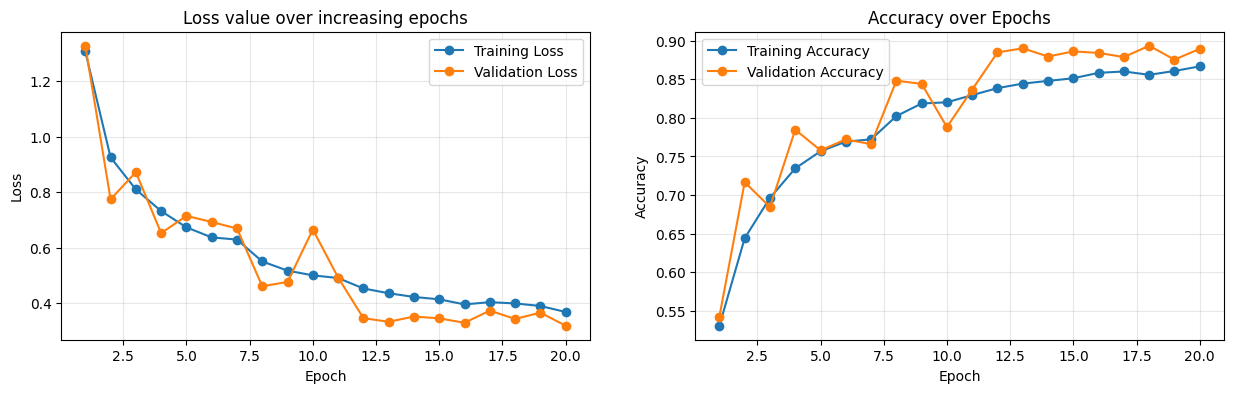

In [18]:
# plot loss and accuracy of training and validation
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))
plt.subplot(121)  # left plot: loss
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)  # right plot: accuracy
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Analysis & Discussion of Results

**Loss and accuracy curves:** The training loss went from 1.3081 to 0.3686 and the validation loss went from 1.3285 to 0.3191. Training accuracy reached 86.66% and validation accuracy reached 88.93% (the best validation accuracy was 89.33% at epoch 18). The two curves stay close and the validation accuracy is even a bit higher than the training accuracy, so the model is not overfitting. I think this happens because the training accuracy is measured while augmentation and dropout are on, but in validation they are off. The validation curve jumps up and down in the first 10 epochs (for example at epoch 3, 5 and 10) and becomes smoother later, after the scheduler reduced the learning rate. The curves are still improving slowly at epoch 20, so more epochs may give a little better result.

**Test result:** The model got 88.53% accuracy on the test set (test loss 0.3566), which is close to the final validation accuracy (88.93%). This shows that the model also works on images it did not see during training. The saved model gave the same 88.53% after loading, so the saving and loading works.

**Class wise result:** The best class was forest (F1-score 0.97, 225 of 228 images correct) and then sea (F1-score 0.91). The worst classes were glacier and mountain (F1-score 0.84 for both). In the confusion matrix mountain and glacier are mixed up the most (31 mountain images were predicted as glacier and 26 glacier images were predicted as mountain). Buildings and street are also mixed up (28 buildings images were predicted as street and 13 street images were predicted as buildings). I think it is because glacier and mountain both have snow, rocks and sky, and street images usually have buildings in them.

**My choices:** I used augmentation and dropout to reduce overfitting and BatchNorm to make the training stable. The ReduceLROnPlateau scheduler made the learning rate smaller when the validation loss stopped improving, which helped the later epochs to be more stable.

## 9. Conclusions & Future Work

I trained a CNN with 4 conv blocks from scratch on the Intel Image Classification dataset and got 88.53% test accuracy on 6 classes.

The model is very good at forest and sea, but it mixes up glacier with mountain and buildings with street. Some of these images are hard even for humans, and I trained the model only one time with one setting.

In future I can train for more epochs (the curves were still improving at epoch 20), try transfer learning (VGG16 or ResNet), different learning rates and dropout values, more augmentation, and Grad-CAM to see what the model looks at.

## Save and Load the Model

I saved only the weights (state_dict) as model.pth. The file is 9.96 MB, which is less than 20 MB, so I uploaded it to GitHub. To check it, I made a new model, loaded the saved weights and tested it again. It gave the same test accuracy (88.53%).

In [19]:
# save only the weights (state_dict)
torch.save(model.state_dict(), 'model.pth')
print("Model size: %.2f MB" % (os.path.getsize('model.pth') / 1e6))

Model size: 9.96 MB


In [20]:
# load the saved weights in a new model and check that it gives the same test accuracy
saved_model = get_model()[0]  # new model with random weights
saved_model.load_state_dict(torch.load('model.pth'))  # put the saved weights in it
saved_model.eval()  # evaluation mode

t_loss, t_acc = validation(test_dl, saved_model, loss_fn)
print(f'Loaded model test accuracy: {t_acc*100:.2f}%')

Loaded model test accuracy: 88.53%
